# NOTEBOOK 01: DATASET EXPLORATION & CLINICAL VISUALIZATION
## Diabetes Multi-Agent AI Support System
**Dataset**: `diabetes_prediction_dataset.csv` (100,000 patient records)
**Target Variable**: `diabetes` (0 = Non-diabetic, 1 = Diabetic)


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette("tab10")
plt.rcParams['font.size'] = 11

DATASET_PATH = os.path.join("..", "datasets", "raw", "diabetes_prediction_dataset.csv")
print(f"Loading dataset from: {DATASET_PATH}")
df = pd.read_csv(DATASET_PATH)
print(f"Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(5)


Loading dataset from: ..\datasets\raw\diabetes_prediction_dataset.csv


Shape: 100,000 rows, 9 columns


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### 1.1 Target Class Imbalance Analysis (Donut Chart & Bar Chart)

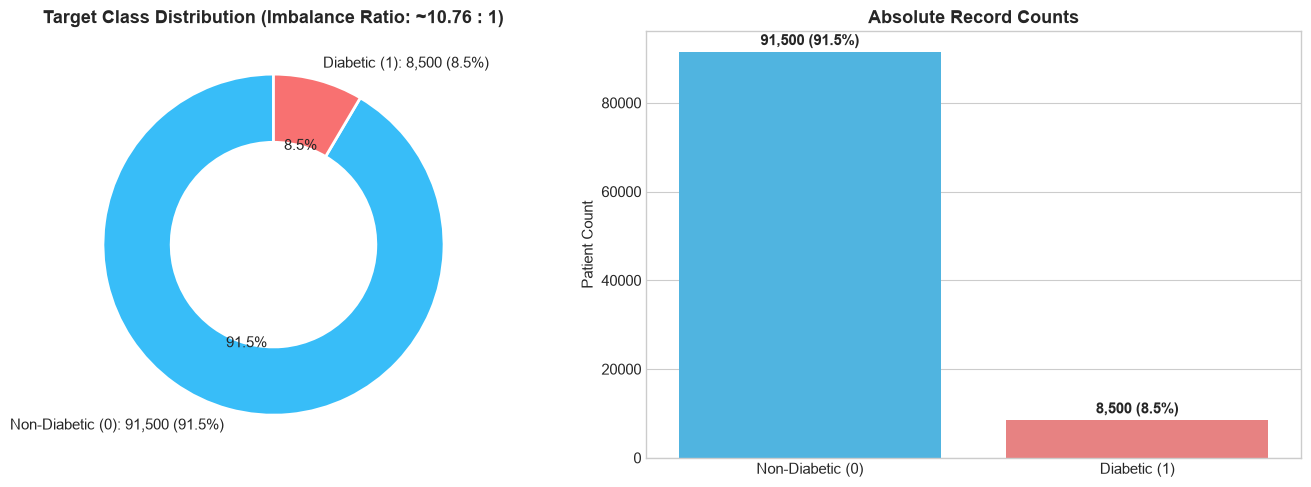

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Donut Chart
counts = df['diabetes'].value_counts()
labels = [f"Non-Diabetic (0): {counts[0]:,} ({counts[0]/len(df)*100:.1f}%)",
          f"Diabetic (1): {counts[1]:,} ({counts[1]/len(df)*100:.1f}%)"]
colors = ['#38bdf8', '#f87171']
axes[0].pie(counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, 
            wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[0].set_title("Target Class Distribution (Imbalance Ratio: ~10.76 : 1)", fontsize=13, fontweight='bold')

# Bar Chart
sns.barplot(x=['Non-Diabetic (0)', 'Diabetic (1)'], y=counts.values, palette=colors, ax=axes[1], hue=['Non-Diabetic (0)', 'Diabetic (1)'], legend=False)
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 1500, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')
axes[1].set_ylabel("Patient Count")
axes[1].set_title("Absolute Record Counts", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 1.2 Continuous Biomarker Distributions (Histograms & KDE)

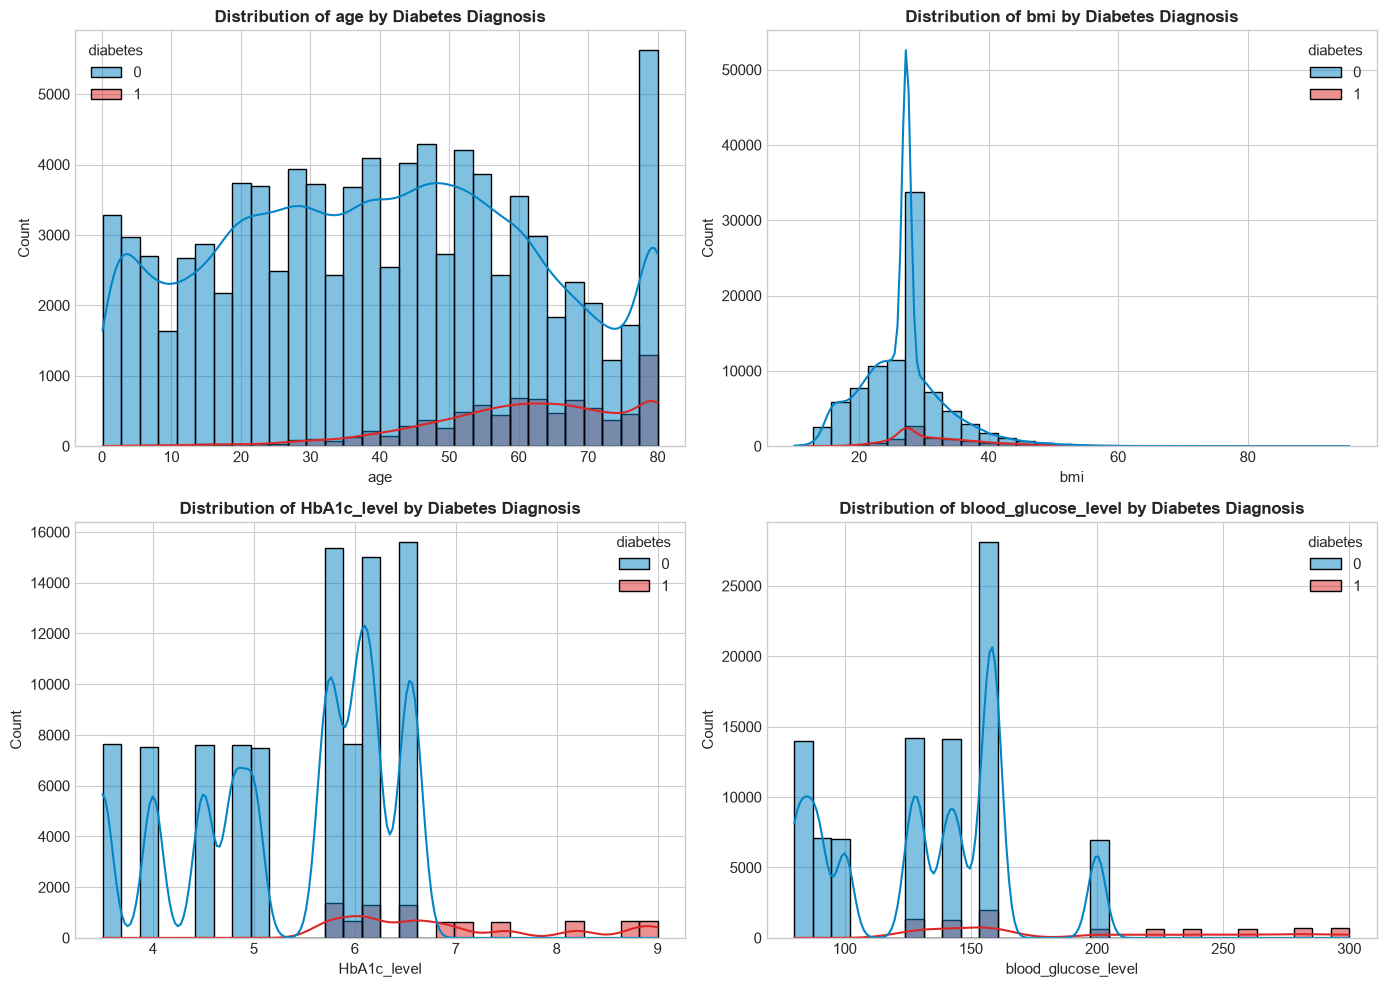

In [3]:
num_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, col in enumerate(num_cols):
    ax = axes[idx // 2, idx % 2]
    sns.histplot(data=df, x=col, kde=True, hue='diabetes', bins=30, ax=ax, 
                 palette={0: '#0284c7', 1: '#dc2626'}, alpha=0.5)
    ax.set_title(f"Distribution of {col} by Diabetes Diagnosis", fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()


### 1.3 ADA Clinical Diagnostic Thresholds (Violin & Boxplots)
American Diabetes Association (ADA) criteria:
- **HbA1c**: $<5.7\%$ (Normal), $5.7\% - 6.4\%$ (Prediabetes), $\ge 6.5\%$ (Diabetes)
- **Fasting Glucose**: $<100\, mg/dL$ (Normal), $100-125\, mg/dL$ (Prediabetes), $\ge 126\, mg/dL$ (Diabetes)


C:\Users\Admin\AppData\Local\Temp\ipykernel_24532\3632996319.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='diabetes', y='HbA1c_level', palette=['#93c5fd', '#fca5a5'], ax=axes[0], inner='box')


C:\Users\Admin\AppData\Local\Temp\ipykernel_24532\3632996319.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])
C:\Users\Admin\AppData\Local\Temp\ipykernel_24532\3632996319.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='diabetes', y='blood_glucose_level', palette=['#93c5fd', '#fca5a5'], ax=axes[1], inner='box')


C:\Users\Admin\AppData\Local\Temp\ipykernel_24532\3632996319.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])


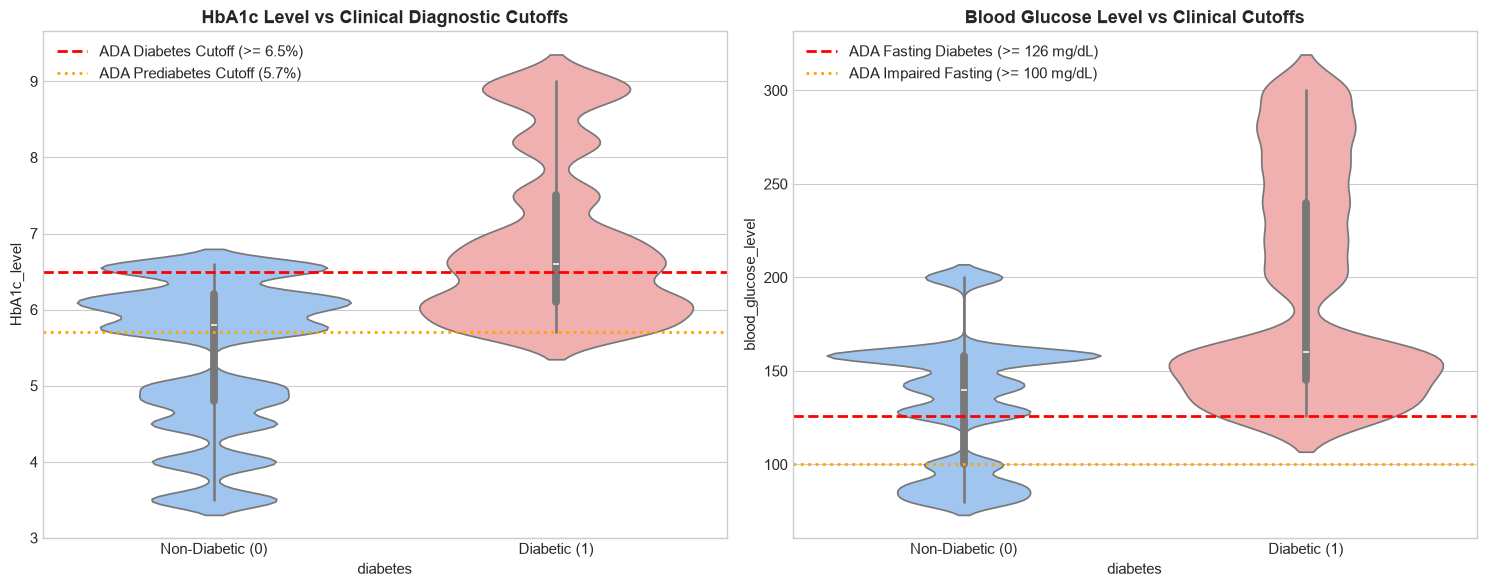

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# HbA1c with ADA threshold
sns.violinplot(data=df, x='diabetes', y='HbA1c_level', palette=['#93c5fd', '#fca5a5'], ax=axes[0], inner='box')
axes[0].axhline(y=6.5, color='red', linestyle='--', linewidth=2, label='ADA Diabetes Cutoff (>= 6.5%)')
axes[0].axhline(y=5.7, color='orange', linestyle=':', linewidth=2, label='ADA Prediabetes Cutoff (5.7%)')
axes[0].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])
axes[0].set_title("HbA1c Level vs Clinical Diagnostic Cutoffs", fontsize=13, fontweight='bold')
axes[0].legend(loc='upper left')

# Glucose with ADA threshold
sns.violinplot(data=df, x='diabetes', y='blood_glucose_level', palette=['#93c5fd', '#fca5a5'], ax=axes[1], inner='box')
axes[1].axhline(y=126, color='red', linestyle='--', linewidth=2, label='ADA Fasting Diabetes (>= 126 mg/dL)')
axes[1].axhline(y=100, color='orange', linestyle=':', linewidth=2, label='ADA Impaired Fasting (>= 100 mg/dL)')
axes[1].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])
axes[1].set_title("Blood Glucose Level vs Clinical Cutoffs", fontsize=13, fontweight='bold')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()


### 1.4 Categorical Risk Factor Analysis & Prevalence Rates

C:\Users\Admin\AppData\Local\Temp\ipykernel_24532\4034949929.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=gender_rates.index, y=gender_rates.values, palette='Blues_d', ax=axes[0])
C:\Users\Admin\AppData\Local\Temp\ipykernel_24532\4034949929.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=smoke_rates.index, y=smoke_rates.values, palette='Reds_d', ax=axes[1])
C:\Users\Admin\AppData\Local\Temp\ipykernel_24532\4034949929.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(smoke_rates.index, rotation=30)


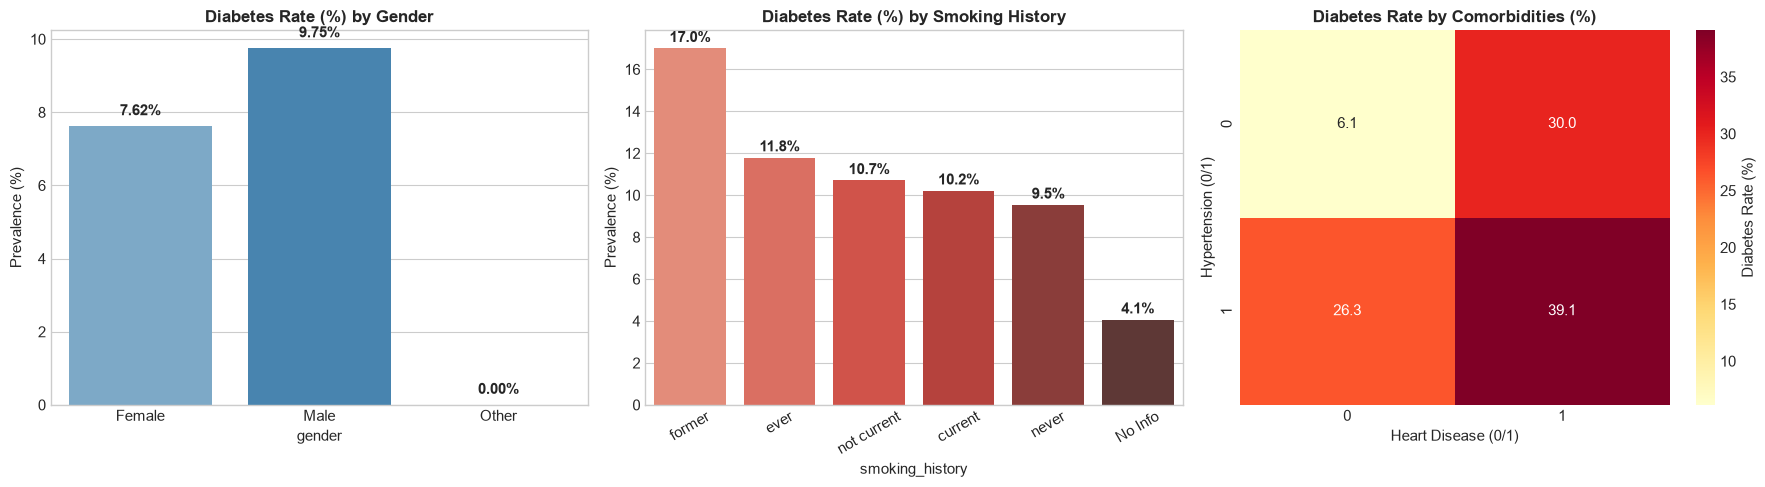

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gender vs Diabetes Rate
gender_rates = df.groupby('gender')['diabetes'].mean() * 100
sns.barplot(x=gender_rates.index, y=gender_rates.values, palette='Blues_d', ax=axes[0])
for i, v in enumerate(gender_rates.values):
    axes[0].text(i, v + 0.3, f"{v:.2f}%", ha='center', fontweight='bold')
axes[0].set_title("Diabetes Rate (%) by Gender", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Prevalence (%)")

# Smoking History vs Diabetes Rate
smoke_rates = df.groupby('smoking_history')['diabetes'].mean().sort_values(ascending=False) * 100
sns.barplot(x=smoke_rates.index, y=smoke_rates.values, palette='Reds_d', ax=axes[1])
for i, v in enumerate(smoke_rates.values):
    axes[1].text(i, v + 0.3, f"{v:.1f}%", ha='center', fontweight='bold')
axes[1].set_title("Diabetes Rate (%) by Smoking History", fontsize=12, fontweight='bold')
axes[1].set_xticklabels(smoke_rates.index, rotation=30)
axes[1].set_ylabel("Prevalence (%)")

# Comorbidity: Hypertension & Heart Disease
comorbid = df.groupby(['hypertension', 'heart_disease'])['diabetes'].mean().unstack() * 100
sns.heatmap(comorbid, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[2], cbar_kws={'label': 'Diabetes Rate (%)'})
axes[2].set_title("Diabetes Rate by Comorbidities (%)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Heart Disease (0/1)")
axes[2].set_ylabel("Hypertension (0/1)")

plt.tight_layout()
plt.show()


### 1.5 Bivariate Scatter Quadrant (HbA1c vs Blood Glucose)

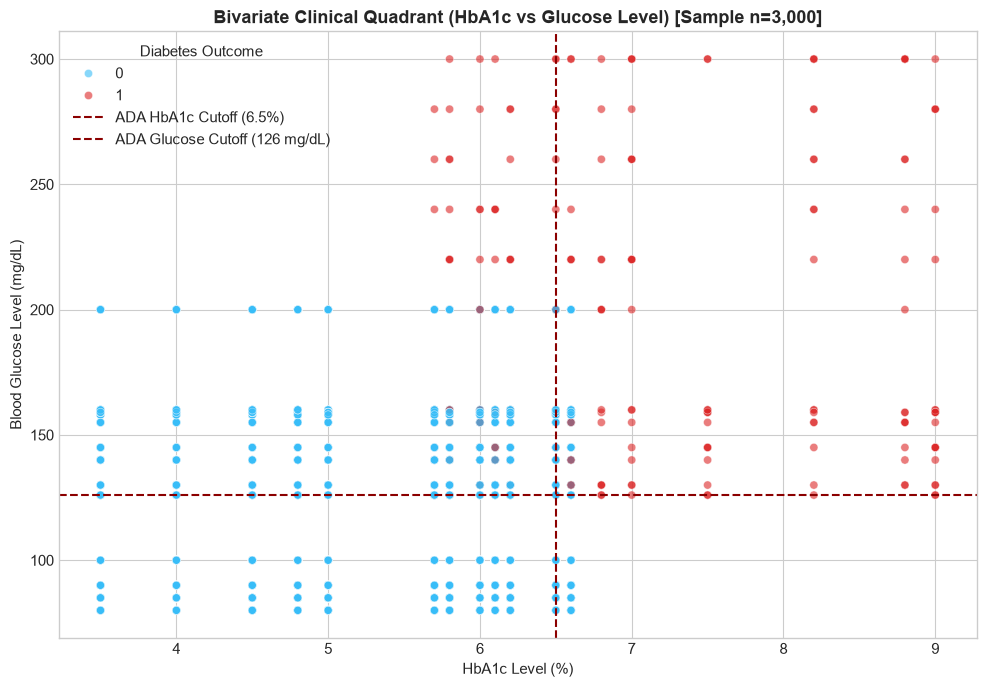

In [6]:
plt.figure(figsize=(10, 7))
sample_df = df.sample(n=3000, random_state=42)
sns.scatterplot(data=sample_df, x='HbA1c_level', y='blood_glucose_level', hue='diabetes', 
                palette={0: '#38bdf8', 1: '#dc2626'}, alpha=0.6, s=35)
plt.axvline(x=6.5, color='darkred', linestyle='--', linewidth=1.5, label='ADA HbA1c Cutoff (6.5%)')
plt.axhline(y=126, color='darkred', linestyle='--', linewidth=1.5, label='ADA Glucose Cutoff (126 mg/dL)')
plt.title("Bivariate Clinical Quadrant (HbA1c vs Glucose Level) [Sample n=3,000]", fontsize=13, fontweight='bold')
plt.xlabel("HbA1c Level (%)")
plt.ylabel("Blood Glucose Level (mg/dL)")
plt.legend(title="Diabetes Outcome", loc='upper left')
plt.tight_layout()
plt.show()


### 1.6 Correlation Matrix Heatmap

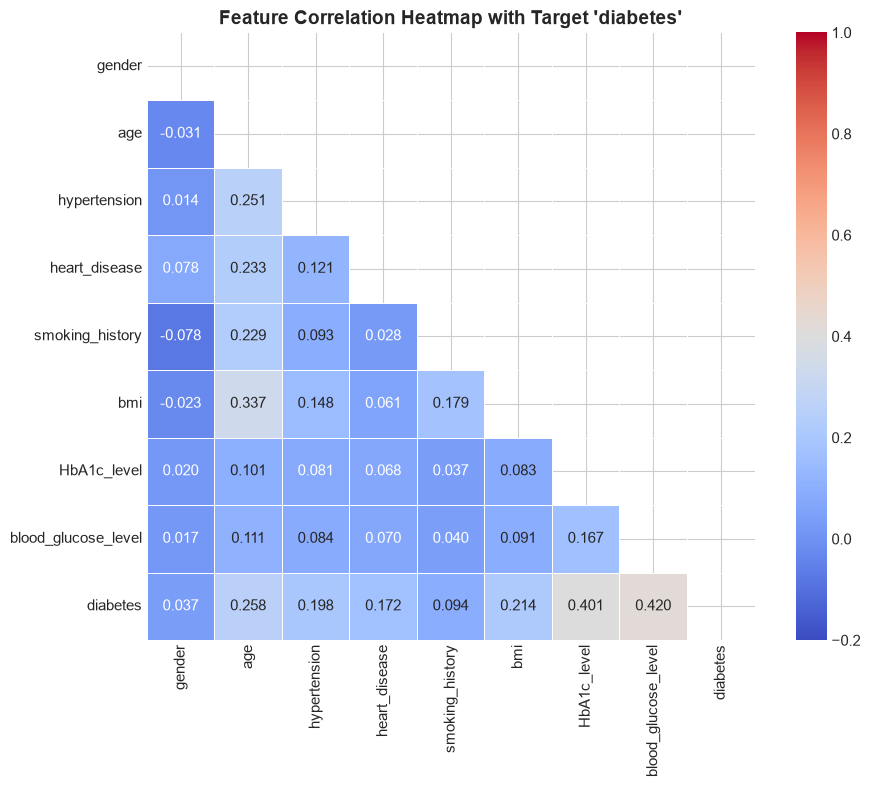

In [7]:
# Compute correlation for numerical + encoded columns
corr_df = df.copy()
corr_df['gender'] = corr_df['gender'].astype('category').cat.codes
corr_df['smoking_history'] = corr_df['smoking_history'].astype('category').cat.codes
corr_matrix = corr_df.corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap='coolwarm', vmin=-0.2, vmax=1.0, 
            mask=mask, square=True, linewidths=0.5)
plt.title("Feature Correlation Heatmap with Target 'diabetes'", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
